# Лабораторная работа № 1. Прогноз кредитного риска

**Выполнил:** Журавлев Андрей  
**Группа:** М8О-312БВ-24

Для запуска нужны NumPy, pandas, Matplotlib, SciPy и scikit-learn. Файлы `train.csv`, `test.csv` и `ex.csv` лежат рядом с ноутбуком. Последняя ячейка записывает `submission.csv`.

## 1. Загрузка и очистка данных

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize
from scipy.special import expit, ndtr
from sklearn.linear_model import (
    ElasticNet, Lasso, LinearRegression as SkLinearRegression, Ridge, SGDRegressor,
)
from sklearn.metrics import (
    mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score,
)
from sklearn.model_selection import KFold, LeaveOneOut
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
TARGET = 'RiskScore'
DATA = Path('.')
train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')
example = pd.read_csv(DATA / 'ex.csv')
columns = test.columns.drop('ID')
assert set(train.columns) == {*columns, TARGET}
assert test['ID'].is_unique and example['ID'].is_unique
assert set(test['ID']) == set(example['ID'])
display(pd.DataFrame({'train': train.shape, 'test': test.shape}, index=['Строки', 'Столбцы']))
display(pd.DataFrame({'train': train.isna().sum(), 'test': test.isna().sum()}).fillna(0).astype(int))

,train,test
Строки,11017,5000
Столбцы,35,35


,train,test
Age,530,0
AnnualIncome,530,0
ApplicationDate,530,0
BankruptcyHistory,1031,0
BaseInterestRate,1031,0
CheckingAccountBalance,1031,0
CreditCardUtilizationRate,530,0
CreditScore,1031,0
DebtToIncomeRatio,530,0
EducationLevel,530,0


In [2]:
target_counts = train[TARGET].value_counts()
sentinels = [-9_999_999, 10_000_000]
display(target_counts.reindex(sentinels).rename('Число записей').to_frame())

valid_target = train[TARGET].notna() & ~train[TARGET].isin(sentinels)
complete = train.loc[valid_target].dropna()
clean = complete.drop_duplicates().reset_index(drop=True)
display(pd.Series({
    'Строки в исходном train': len(train),
    'Пропуск цели': int(train[TARGET].isna().sum()),
    'Служебные значения цели': int(train[TARGET].isin(sentinels).sum()),
    'Пропуск признака при корректной цели': int(valid_target.sum() - len(complete)),
    'Точные повторы среди оставшихся строк': len(complete) - len(clean),
    'Строки после очистки': len(clean),
}).to_frame('Количество'))
display(clean[TARGET].describe().to_frame())

,Число записей
RiskScore,
-9999999,121
10000000,94


,Количество
Строки в исходном train,11017
Пропуск цели,530
Служебные значения цели,215
Пропуск признака при корректной цели,485
Точные повторы среди оставшихся строк,455
Строки после очистки,9332


,RiskScore
count,9332.000000
mean,48.312511
std,17.243078
min,14.841417
25%,32.693275
50%,44.127496
75%,65.059406
max,97.597249


В `train.csv` 530 пропущенных `RiskScore`, ещё 215 значений сконцентрированы в двух точках около $-10^7$ и $10^7$. Остальные значения риска лежат примерно между 15 и 98. Убираем эти две аномалии и записи с пропусками в признаках, поскольку тестовая выборка полностью заполнена. Точные повторы удаляем до разбиения, чтобы одна заявка не оказалась одновременно в обучении и валидации. После очистки остаётся **9 332** уникальные записи.

## 2. Разведочный анализ

### 2.1. Распределение целевой переменной

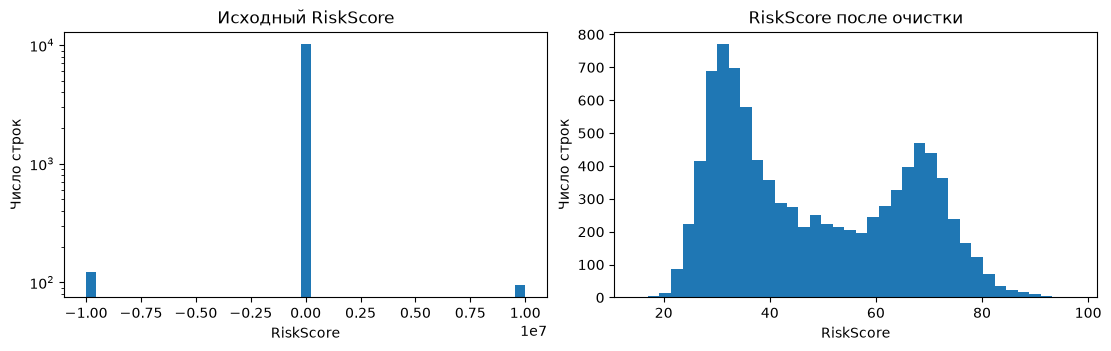

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), layout='constrained')
axes[0].hist(train[TARGET].dropna(), bins=45, color='tab:blue')
axes[0].set(title='Исходный RiskScore', xlabel='RiskScore', ylabel='Число строк', yscale='log')
axes[1].hist(clean[TARGET], bins=38, color='tab:blue')
axes[1].set(title='RiskScore после очистки', xlabel='RiskScore', ylabel='Число строк')
plt.show()

После очистки видны два пика. Чтобы понять, что их разделяет, посмотрим на связи цели с доходом и кредитным рейтингом.

### 2.2. Связи между признаками и целью

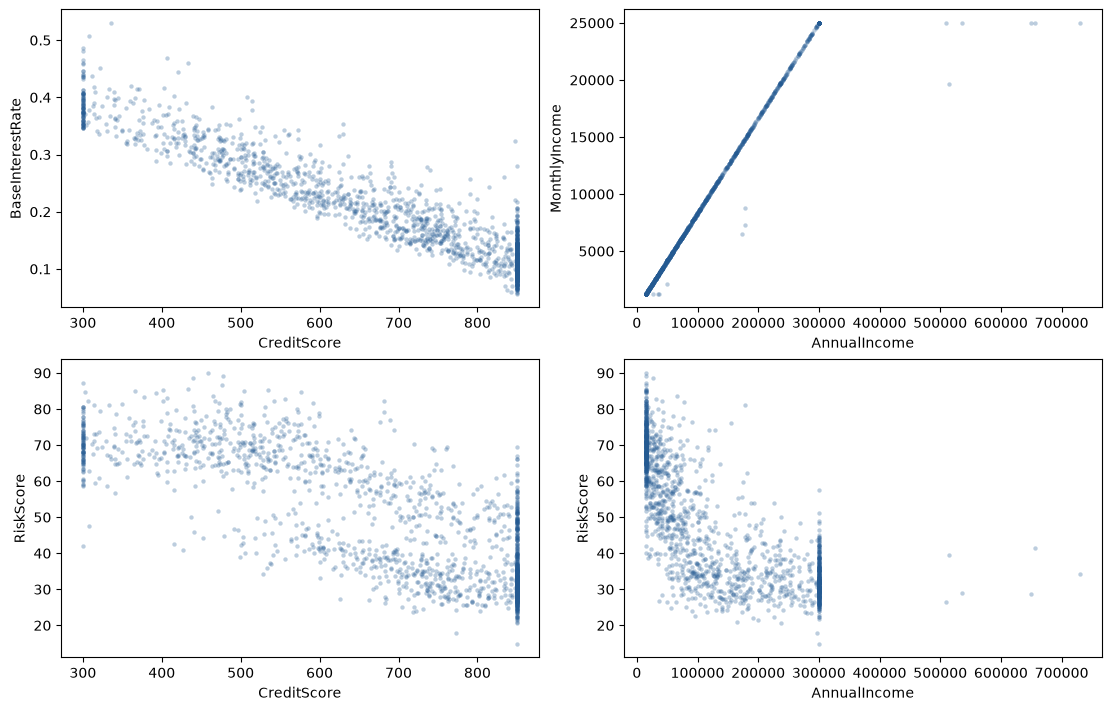

In [4]:
sample = clean.sample(1600, random_state=SEED)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout='constrained')
pairs = [
    ('CreditScore', 'BaseInterestRate'),
    ('AnnualIncome', 'MonthlyIncome'),
    ('CreditScore', TARGET),
    ('AnnualIncome', TARGET),
]
for ax, (left, right) in zip(axes.flat, pairs):
    ax.scatter(sample[left], sample[right], s=10, alpha=.3, color='#245a92', linewidths=0)
    ax.set(xlabel=left, ylabel=right)
plt.show()

### 2.3. Матрица корреляций

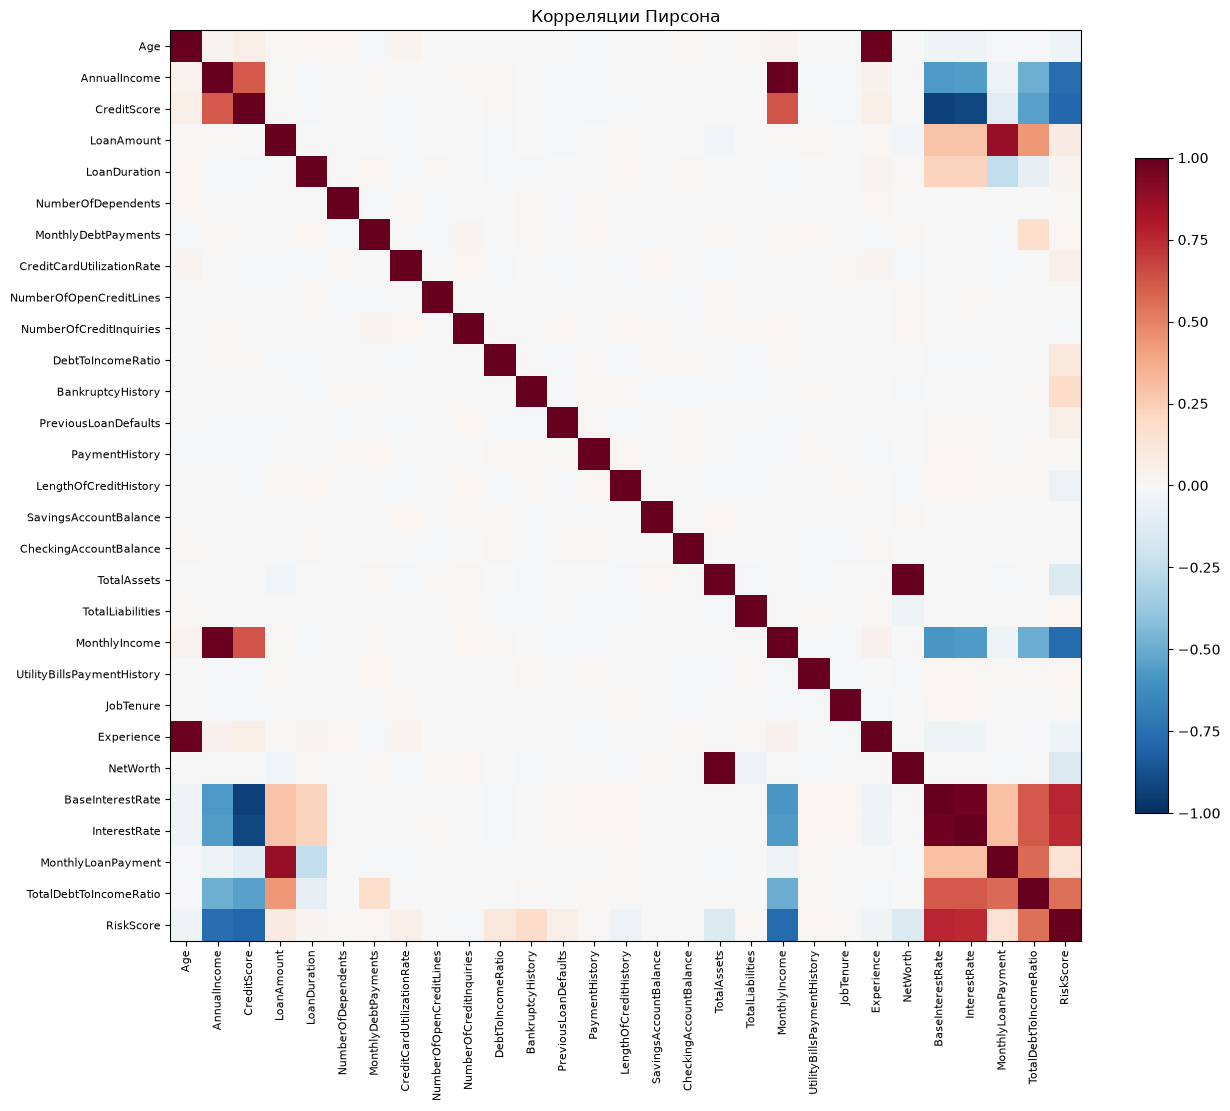

CreditScore              -0.785429
MonthlyIncome            -0.770341
BaseInterestRate          0.759546
AnnualIncome             -0.757874
InterestRate              0.744193
TotalDebtToIncomeRatio    0.554352
BankruptcyHistory         0.179697
TotalAssets              -0.147472
MonthlyLoanPayment        0.147417
NetWorth                 -0.146222
Name: RiskScore, dtype: float64

In [5]:
corr = clean.select_dtypes(include='number').corr()
fig, ax = plt.subplots(figsize=(13, 11), layout='constrained')
heatmap = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set(xticks=np.arange(len(corr)), yticks=np.arange(len(corr)), title='Корреляции Пирсона')
ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticklabels(corr.columns, fontsize=8)
fig.colorbar(heatmap, ax=ax, shrink=.72)
plt.show()
display(corr[TARGET].drop(TARGET).sort_values(key=lambda s: s.abs(), ascending=False).head(10))

Рейтинг и доход сильнее всего отрицательно связаны с риском. Ставка и отношение общих платежей к доходу связаны с ним положительно. График дохода показывает, что связь месячного и годового доходов почти линейная, но месячный доход ограничен сверху. На графиках цели различимы две полосы с меняющимся расстоянием между ними. Поэтому сравним обычную регрессию, модель с расширенным набором признаков и скоринговую карту с поправкой на полосу.

## 3. Нормализация и метрики

Z-score вычисляется как $(x-\mu)/\sigma$, min-max — как $(x-\min)/(\max-\min)$. Для константного столбца используем делитель 1. Параметры нормализации вычисляются по обучающей части каждого разбиения.

MAPE возвращается в долях. Для нулевых истинных значений применяем машинный эпсилон, как в scikit-learn. Для постоянной цели R² равен 1 при точном предсказании и 0 при ненулевой ошибке.

### 3.1. Z-score и min-max

In [6]:
class Scaler:
    def __init__(self, method='zscore'):
        self.method = method

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        if self.method == 'zscore':
            self.offset_ = X.mean(axis=0)
            scale = X.std(axis=0)
        elif self.method == 'minmax':
            self.offset_ = X.min(axis=0)
            scale = X.max(axis=0) - self.offset_
        else:
            raise ValueError(f'Неизвестная нормализация: {self.method}')
        self.scale_ = np.where(scale == 0, 1, scale)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.offset_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)




small = np.array([[1, 5], [2, 5], [4, 5]], dtype=float)
for method, reference in [('zscore', StandardScaler()), ('minmax', MinMaxScaler())]:
    expected = reference.fit_transform(small)
    got = Scaler(method).fit_transform(small)
    np.testing.assert_allclose(got, expected, atol=1e-12)

### 3.2. MSE, MAE, R² и MAPE

In [7]:
def mse(y, pred):
    return np.mean((np.asarray(y, dtype=float) - pred) ** 2)


def mae(y, pred):
    return np.mean(np.abs(np.asarray(y, dtype=float) - pred))


def r2(y, pred):
    y = np.asarray(y, dtype=float)
    if len(y) < 2:
        return np.nan
    variance = np.mean((y - y.mean()) ** 2)
    error = mse(y, pred)
    return float(error == 0) if variance == 0 else 1 - error / variance


def mape(y, pred):
    y = np.asarray(y, dtype=float)
    denominator = np.maximum(np.abs(y), np.finfo(float).eps)
    return np.mean(np.abs(y - pred) / denominator)


metrics = {'MSE': mse, 'MAE': mae, 'R²': r2, 'MAPE': mape}
sk_metrics = {
    'MSE': mean_squared_error, 'MAE': mean_absolute_error,
    'R²': r2_score, 'MAPE': mean_absolute_percentage_error,
}



for y_check, pred_check in [
    ([1, 2, 4], [2, 2, 3]), ([0, 2, 4], [1, 2, 3]),
    ([3, 3, 3], [3, 3, 3]), ([3, 3, 3], [3, 3, 2]),
]:
    for name, metric in metrics.items():
        np.testing.assert_allclose(metric(y_check, pred_check), sk_metrics[name](y_check, pred_check))

display(pd.DataFrame([
    {'Метрика': name, 'Реализация': metric([1, 2, 4], [2, 2, 3]),
     'scikit-learn': sk_metrics[name]([1, 2, 4], [2, 2, 3])}
    for name, metric in metrics.items()
]).set_index('Метрика'))

,Реализация,scikit-learn
Метрика,,
MSE,0.666667,0.666667
MAE,0.666667,0.666667
R²,0.571429,0.571429
MAPE,0.416667,0.416667


## 4. Линейная регрессия

В модели $\hat y=Xw+b$ минимизируем $\tfrac{1}{2n}\|y-\hat y\|^2$. Аналитическое решение OLS записывается через псевдообратную матрицу $w=X_c^+y_c$ для центрированных данных. SVD позволяет учитывать линейно зависимые признаки. Свободный член восстанавливаем по средним.

Градиентный спуск считает градиент по всему батчу, SGD обновляет веса по одной случайной записи. В SGD используем убывающий шаг и усредняем веса последних эпох.

Для регуляризации добавляем $\lambda_1\sum_j|w_j|+\tfrac{\lambda_2}{2}\sum_jw_j^2$. При L1 используем проксимальный шаг с мягким порогом. Для произвольного $p>1$ добавляем $\tfrac{\lambda_p}{p}\sum_j|w_j|^p$ и минимизируем гладкую функцию методом L-BFGS. При $p=1$ применяется L1. Свободный член исключён из штрафа.

In [8]:
class LinearRegression:
    def __init__(self, method='analytic', *, l1=0., l2=0., lp=0., p=2.,
                 epochs=40, max_iter=12000, tol=1e-8, random_state=SEED):
        if min(l1, l2, lp) < 0 or not np.isfinite(p) or p < 1:
            raise ValueError('Коэффициенты штрафа должны быть неотрицательными, p ≥ 1')
        if method not in {'analytic', 'gd', 'sgd', 'proximal', 'lp'}:
            raise ValueError(f'Неизвестный метод обучения: {method}')
        if (l1 and method != 'proximal') or (lp and method != 'lp'):
            raise ValueError('Для L1 используйте proximal, для Lp используйте lp')
        self.method = method
        self.l1, self.l2, self.lp, self.p = l1, l2, lp, p
        self.epochs, self.max_iter, self.tol = epochs, max_iter, tol
        self.random_state = random_state

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        x_mean, y_mean = X.mean(axis=0), y.mean()
        A, target = X - x_mean, y - y_mean
        n, d = A.shape
        self.loss_curve_ = []

        if self.method == 'analytic':
            if self.l2:
                gram = A.T @ A / n + self.l2 * np.eye(d)
                w = np.linalg.solve(gram, A.T @ target / n)
            else:
                w = np.linalg.lstsq(A, target, rcond=None)[0]
        elif self.method == 'sgd':
            w = np.zeros(d)
            average = np.zeros(d)
            rng = np.random.default_rng(self.random_state)
            max_row_norm = np.einsum('ij,ij->i', A, A).max()
            initial_step = 0.5 / max(float(max_row_norm) + self.l2, 1.)
            for epoch in range(self.epochs):
                step = initial_step / np.sqrt(1 + epoch / 5)
                for index in rng.permutation(n):
                    row = A[index]
                    w -= step * ((row @ w - target[index]) * row + self.l2 * w)
                self.loss_curve_.append(mse(target, A @ w))
                if epoch >= self.epochs // 2:
                    average += w
            w = average / (self.epochs - self.epochs // 2)
        else:
            gram = A.T @ A / n + self.l2 * np.eye(d)
            rhs = A.T @ target / n
            if self.method == 'lp' and self.p > 1:
                def objective(w):
                    gram_w = gram @ w
                    penalty = self.lp * np.sum(np.abs(w) ** self.p) / self.p
                    gradient = self.lp * np.sign(w) * np.abs(w) ** (self.p - 1)
                    return .5 * w @ gram_w - rhs @ w + penalty, gram_w - rhs + gradient

                result = minimize(
                    objective, np.zeros(d), method='L-BFGS-B', jac=True,
                    options={'maxiter': self.max_iter, 'gtol': self.tol, 'ftol': 1e-14},
                )
                if not result.success:
                    raise RuntimeError(result.message)
                w = result.x
            else:
                threshold = self.lp if self.method == 'lp' else self.l1
                step = 1 / max(float(np.linalg.eigvalsh(gram)[-1]), 1e-12)
                w = point = np.zeros(d)
                momentum = 1.
                for iteration in range(self.max_iter):
                    updated = point - step * (gram @ point - rhs)
                    if threshold:
                        updated = np.sign(updated) * np.maximum(np.abs(updated) - step * threshold, 0)
                    if iteration % 50 == 0:
                        self.loss_curve_.append(mse(target, A @ updated))
                    if np.linalg.norm(updated - w) <= self.tol * (1 + np.linalg.norm(w)):
                        w = updated
                        break
                    if self.method == 'gd':
                        point = updated
                    else:
                        next_momentum = (1 + np.sqrt(1 + 4 * momentum ** 2)) / 2
                        point = updated + (momentum - 1) / next_momentum * (updated - w)
                        momentum = next_momentum
                    w = updated
        self.coef_ = w
        self.intercept_ = y_mean - x_mean @ w
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

### 4.1. Сравнение аналитического решения, GD и SGD

In [9]:
KEY = [
    'AnnualIncome', 'CreditScore', 'TotalDebtToIncomeRatio', 'BaseInterestRate',
    'InterestRate', 'LoanAmount', 'MonthlyDebtPayments', 'MonthlyIncome',
    'DebtToIncomeRatio', 'NetWorth', 'MonthlyLoanPayment',
]
RISK_FACTORS = [
    'BankruptcyHistory', 'PreviousLoanDefaults', 'NumberOfCreditInquiries',
    'Age', 'CreditCardUtilizationRate', 'PaymentHistory', 'AnnualIncome',
    'MonthlyIncome', 'DebtToIncomeRatio', 'LengthOfCreditHistory', 'CreditScore',
]
INTERACTION_FACTORS = [
    'BankruptcyHistory', 'PreviousLoanDefaults', 'CreditScore',
    'AnnualIncome', 'TotalDebtToIncomeRatio',
]


class Features:
    def __init__(self, extended=False, scaling='zscore'):
        self.extended = extended
        self.scaler = Scaler(scaling)

    def fit(self, frame):
        raw = frame.drop(columns='ApplicationDate')
        self.numeric_ = list(raw.select_dtypes(include='number'))
        self.categories_ = {
            col: sorted(raw[col].unique()) for col in raw if col not in self.numeric_
        }
        if self.extended:
            numeric = raw[self.numeric_]
            self.knots_ = numeric.quantile([.05, .15, .30, .50, .70, .85, .95])
            self.interaction_knots_ = numeric[KEY[:3]].quantile([.15, .35, .55, .75, .90])
        self.scaler.fit(self.design(frame))
        return self

    def design(self, frame):
        num = frame[self.numeric_].astype(float)
        result = {col: num[col] for col in self.numeric_}
        for col, values in self.categories_.items():
            for value in values[1:]:
                result[f'{col}={value}'] = frame[col].eq(value).astype(float)
        if self.extended:
            log = np.log1p(num)
            for col, values in num.items():
                result[f'log({col})'] = log[col]
                result[f'{col}^2'] = values ** 2
                for knot in self.knots_[col].unique():
                    result[f'({col}-{knot:g})+'] = (values - knot).clip(lower=0)

            for left, right in combinations(sorted(KEY), 2):
                result[f'{left}*{right}'] = num[left] * num[right]
                result[f'log({left})*log({right})'] = log[left] * log[right]

            for col in KEY:
                for cap in (30_000, 60_000, 100_000):
                    result[f'log({col})*income≤{cap}'] = log[col] * num['AnnualIncome'].clip(upper=cap)
                for cap in (.3, .5, 1.):
                    result[f'log({col})*dti≤{cap}'] = log[col] * num['TotalDebtToIncomeRatio'].clip(upper=cap)

            for left in RISK_FACTORS:
                for right in INTERACTION_FACTORS:
                    if left != right:
                        first, second = sorted((left, right))
                        result[f'log({first})*log({second})'] = log[first] * log[second]

            for col in ('LoanAmount', 'MonthlyDebtPayments', 'NetWorth', 'MonthlyLoanPayment'):
                for income in ('AnnualIncome', 'MonthlyIncome'):
                    ratio = num[col] / num[income]
                    result[f'{col}/{income}'] = ratio
                    result[f'log({col}/{income})'] = np.log1p(ratio)

            for left, right in combinations(KEY[:3], 2):
                for a in self.interaction_knots_[left].unique():
                    for b in self.interaction_knots_[right].unique():
                        left_hinge = np.log1p((num[left] - a).clip(lower=0))
                        right_hinge = np.log1p((num[right] - b).clip(lower=0))
                        result[f'log(({left}-{a:g})+)*log(({right}-{b:g})+)'] = left_hinge * right_hinge

        return pd.DataFrame(result, index=frame.index)

    def transform(self, frame):
        return self.scaler.transform(self.design(frame))

In [10]:
X = clean.loc[:, columns]
y = clean[TARGET].to_numpy()
indices = np.random.default_rng(SEED).permutation(len(y))
valid_idx, fit_idx = np.split(indices, [int(np.ceil(.2 * len(y)))])
X_fit, X_valid = X.iloc[fit_idx], X.iloc[valid_idx]
y_fit, y_valid = y[fit_idx], y[valid_idx]

In [11]:
with threadpool_limits(limits=1):
    basic = Features().fit(X_fit)
    A, B = basic.transform(X_fit), basic.transform(X_valid)
    ols_ref = SkLinearRegression().fit(A, y_fit).predict(B)
    sgd_ref = SGDRegressor(
        penalty=None, average=True, eta0=.001, max_iter=60, tol=None, random_state=SEED,
    ).fit(A, y_fit).predict(B)

    estimates = {'scikit-learn OLS': ols_ref, 'scikit-learn SGD': sgd_ref}
    for method in ('analytic', 'gd', 'sgd'):
        estimates[method] = LinearRegression(method, epochs=60).fit(A, y_fit).predict(B)

    minmax = Features(scaling='minmax').fit(X_fit)
    estimates['analytic min-max'] = LinearRegression().fit(
        minmax.transform(X_fit), y_fit,
    ).predict(minmax.transform(X_valid))

    assert np.sqrt(mse(ols_ref, estimates['gd'])) < .10
    assert np.sqrt(mse(ols_ref, estimates['sgd'])) < 2.
    np.testing.assert_allclose(estimates['analytic'], ols_ref, atol=1e-8)
    np.testing.assert_allclose(estimates['analytic min-max'], ols_ref, atol=1e-8)

display(pd.DataFrame({
    name: {**{key: metric(y_valid, pred) for key, metric in metrics.items()},
           'RMSE относительно OLS': np.sqrt(mse(ols_ref, pred))}
    for name, pred in estimates.items()
}).T.round(6))

,MSE,MAE,R²,MAPE,RMSE относительно OLS
scikit-learn OLS,50.952251,5.717537,0.827127,0.135888,0.000000
scikit-learn SGD,51.497531,5.838464,0.825277,0.136068,0.958927
analytic,50.952251,5.717537,0.827127,0.135888,0.000000
gd,50.952252,5.717537,0.827127,0.135888,0.000006
sgd,51.039724,5.724442,0.826831,0.135953,0.248637
analytic min-max,50.952251,5.717537,0.827127,0.135888,0.000000


На базовых признаках аналитическое решение совпадает с `sklearn.LinearRegression`. В полном градиентном спуске прогноз практически совпадает с аналитическим. SGD сходится к близкой ошибке. Z-score и min-max дают одинаковый прогноз МНК для этой матрицы.

### 4.2. Регуляризация L1, L2, L1+L2 и Lp

При сравнении приводим коэффициенты к одинаковой целевой функции. Для `Ridge` из scikit-learn это $\alpha=n\lambda_2$. Для `Lasso` используем $\alpha=\lambda_1$. Для `ElasticNet` сумма штрафов задаёт $\alpha=\lambda_1+\lambda_2$, а доля L1 равна $\lambda_1/\alpha$. При $p=1$ и $p=2$ сравниваем Lp с Lasso и Ridge. Для других $p$ проверяем качество на том же разбиении.

In [12]:
l1, l2 = .05, .02
regularizers = {
    'L1': (LinearRegression('proximal', l1=l1), Lasso(alpha=l1, tol=1e-10, max_iter=20000)),
    'L2': (LinearRegression(l2=l2), Ridge(alpha=len(y_fit) * l2)),
    'L1+L2': (
        LinearRegression('proximal', l1=l1, l2=l2),
        ElasticNet(alpha=l1 + l2, l1_ratio=l1 / (l1 + l2), tol=1e-10, max_iter=20000),
    ),
}
lp_strength = .08
rows = []
with threadpool_limits(limits=1):
    for name, (model, reference) in regularizers.items():
        predicted = model.fit(A, y_fit).predict(B)
        expected = reference.fit(A, y_fit).predict(B)
        np.testing.assert_allclose(predicted, expected, atol=5e-3, rtol=0)
        rows.append([name, mse(y_valid, predicted), mse(y_valid, expected), np.sqrt(mse(expected, predicted))])

    for p in (1., 1.5, 2., 3.):
        model = LinearRegression('lp', lp=lp_strength, p=p).fit(A, y_fit)
        predicted = model.predict(B)
        if p == 1.:
            expected = Lasso(alpha=lp_strength, tol=1e-8, max_iter=100000).fit(A, y_fit).predict(B)
        elif p == 2.:
            expected = Ridge(alpha=len(y_fit) * lp_strength).fit(A, y_fit).predict(B)
        else:
            expected = None
        if expected is not None:
            np.testing.assert_allclose(predicted, expected, atol=5e-3, rtol=0)
        rows.append([
            f'Lp (p={p:g})', mse(y_valid, predicted),
            mse(y_valid, expected) if expected is not None else np.nan,
            np.sqrt(mse(expected, predicted)) if expected is not None else np.nan,
        ])

display(pd.DataFrame(rows, columns=['Штраф', 'MSE', 'MSE scikit-learn', 'RMSE между прогнозами']))

,Штраф,MSE,MSE scikit-learn,RMSE между прогнозами
0,L1,50.858130,50.858133,1.659389e-05
1,L2,50.975527,50.975527,7.992469e-15
2,L1+L2,50.918888,50.918888,1.719587e-07
3,Lp (p=1),50.792691,50.792688,2.486198e-05
4,Lp (p=1.5),50.908347,NaN,NaN
5,Lp (p=2),51.054706,51.054706,5.327622e-07
6,Lp (p=3),52.095762,NaN,NaN


## 5. Кросс-валидация

В k-fold каждый объект один раз попадает в проверочную часть. Leave-one-out — случай $k=n$. Реализации возвращают индексы обучающей и проверочной частей. LOOCV с переобучением используется для проверки на небольшой подвыборке. Для OLS на всём очищенном train считаем те же ошибки без повторной подгонки через диагональ матрицы проекции $h_{ii}$ и формулу PRESS $e_{(i)}=e_i/(1-h_{ii})$.

In [13]:
def k_fold(n, k, *, shuffle=False, random_state=SEED):
    if not 2 <= k <= n:
        raise ValueError('Требуется 2 ≤ k ≤ n')
    indices = np.arange(n)
    if shuffle:
        indices = np.random.default_rng(random_state).permutation(indices)
    folds = np.array_split(indices, k)
    for i, valid in enumerate(folds):
        train_idx = np.concatenate(folds[:i] + folds[i+1:])
        yield train_idx, valid


def leave_one_out(n):
    if n < 2:
        raise ValueError('Нужно не менее двух наблюдений')
    indices = np.arange(n)
    for i in indices:
        yield indices[indices != i], indices[i:i+1]


def cross_validate(X, y, splits, fit_predict):
    y = np.asarray(y, dtype=float)
    predictions = np.full(len(y), np.nan)
    rows = []
    for fit_idx, valid_idx in splits:
        pred = fit_predict(X.iloc[fit_idx], y[fit_idx], X.iloc[valid_idx])
        predictions[valid_idx] = pred
        rows.append({name: metric(y[valid_idx], pred) for name, metric in metrics.items()})
    if not np.isfinite(predictions).all():
        raise ValueError('Для каждой строки нужен конечный прогноз на проверочной части')
    return pd.DataFrame(rows), predictions


def loo_ols(X, y):
    design = np.column_stack([np.ones(len(X)), np.asarray(X, dtype=float)])
    u, singular, _ = np.linalg.svd(design, full_matrices=False)
    cutoff = np.finfo(float).eps * max(design.shape) * singular[0]
    basis = u[:, singular > cutoff]
    fitted = basis @ (basis.T @ y)
    leverage = np.einsum('ij,ij->i', basis, basis)
    if np.any(np.isclose(leverage, 1, rtol=0, atol=1e-10)):
        raise ValueError('Некоторые исключения изменяют ранг матрицы признаков')
    return y - (y - fitted) / (1 - leverage)


for own, reference in [
    (k_fold(13, 4), KFold(4).split(np.arange(13))),
    (leave_one_out(13), LeaveOneOut().split(np.arange(13))),
]:
    for (own_train, own_valid), (ref_train, ref_valid) in zip(own, reference, strict=True):
        np.testing.assert_array_equal(own_train, ref_train)
        np.testing.assert_array_equal(own_valid, ref_valid)

rng = np.random.default_rng(SEED)
toy_X = pd.DataFrame(rng.normal(size=(24, 4)))
toy_y = rng.normal(size=24)
_, refit = cross_validate(
    toy_X, toy_y, leave_one_out(len(toy_y)),
    lambda A, b, B: LinearRegression().fit(A, b).predict(B),
)
np.testing.assert_allclose(loo_ols(toy_X, toy_y), refit, atol=1e-10)

In [14]:
with threadpool_limits(limits=1):
    loo_features = Features().fit(X)
    assert all(X[col].value_counts().min() >= 2 for col in loo_features.categories_)
    loo_predictions = loo_ols(loo_features.transform(X), y)

display(pd.Series({name: metric(y, loo_predictions) for name, metric in metrics.items()},
                  name='LOOCV, базовый МНК').to_frame())

,"LOOCV, базовый МНК"
MSE,50.775099
MAE,5.717469
R²,0.829208
MAPE,0.134247


PRESS даёт результат полного leave-one-out для базового МНК. Во всех исключениях сохраняются категории. При наличии свободного члена центрирование и масштабирование столбцов сохраняют пространство прогнозов.

В дальнейшем используем одинаковые пять фолдов для сравниваемых моделей. Квантили, параметры нормализации и коэффициенты регрессий оцениваются внутри обучающей части фолда.

## 6. Модель для Kaggle

### 6.1. Базовые варианты

В первой модели используем числовые столбцы и one-hot кодирование категорий. Во второй добавляем логарифмы, отношения кредитных показателей, кусочно-линейные признаки и взаимодействия. L2-штраф сдерживает рост коэффициентов у коррелирующих признаков. Влияние этих преобразований оцениваем по вневыборочным прогнозам.

In [15]:
RIDGE_ALPHA = 5.


def predict_fold(A, y_train, B, *, extended=False, alpha=0.):
    preprocessing = Features(extended=extended).fit(A)
    model = LinearRegression(l2=alpha / len(y_train))
    return model.fit(preprocessing.transform(A), y_train).predict(preprocessing.transform(B))

### 6.2. Пороговая карта и поправка на полосу

На графике цели можно различить две полосы риска. Для их описания зададим линейную скоринговую карту $s(x)=c(x)^\top\beta$. В $c(x)$ входят константа, индикаторы перехода кредитного рейтинга, дохода, долговой нагрузки и других показателей через пороги, а также несколько бинарных признаков. Нижняя полоса имеет среднее $s(x)$, верхняя — $(1+\kappa)s(x)$.

Чтобы получить вес верхней полосы $q(x)$ для новой заявки, вычисляем индекс из её полей и сглаживаем его функцией нормального распределения. Форму индекса взяли как гипотезу из описания генератора синтетических заявок. В архиве месячный доход позволяет восстановить доход для индекса, даже когда годовой доход изменён, а разность активов и обязательств даёт оценку капитала до добавленной вариации. Вес $q(x)$ вычисляется по признакам заявки. Все коэффициенты скоринговой карты и множитель полосы подбираются по `train.csv`.

Для вычисления прогноза используем линейную регрессию на скорректированных признаках:

$$\widehat y(x)=\big[c(x)(1+\kappa q(x))\big]^\top\beta.$$

На обучении уточняем $\beta$ взвешенным МНК. Каждая строка участвует в двух полосах, а её веса — вероятности принадлежности к ним по текущим ошибкам и $q(x)$. Множитель $\kappa$ обновляем одномерной регрессией. Инициализацию жёстким распределением по полосам также проверим отдельно. Оба варианта используют одинаковые пороговые признаки. Центр сглаживания равен 1, ширина 0,5 выбрана по предварительным экспериментам на обучающем наборе и зафиксирована для сравнительных прогонов.

In [16]:
CARD_THRESHOLDS = {
    'CreditScore': (600, 650, 700, 750),
    'AnnualIncome': (30_000, 50_000, 80_000, 120_000),
    'DebtToIncomeRatio': (.2, .3, .4, .5),
    'CreditCardUtilizationRate': (.2, .4, .6, .8),
    'LengthOfCreditHistory': (3, 5, 7, 10),
    'NetWorth': (50_000, 100_000, 250_000, 500_000, 1_000_000),
}


def scorecard_design(frame):
    features = {'Константа': np.ones(len(frame))}
    for col, thresholds in CARD_THRESHOLDS.items():
        for threshold in thresholds:
            features[f'{col} ≥ {threshold:g}'] = frame[col].ge(threshold)
    features['BankruptcyHistory'] = frame['BankruptcyHistory']
    features['PreviousLoanDefaults'] = frame['PreviousLoanDefaults']
    features['Employed'] = frame['EmploymentStatus'].eq('Employed')
    return pd.DataFrame(features, index=frame.index, dtype=float)


def upper_band_weight(frame):
    month = pd.to_datetime(frame['ApplicationDate']).dt.month
    original_income = 12 * frame['MonthlyIncome']
    original_worth = (frame['TotalAssets'] - frame['TotalLiabilities']).clip(lower=1000)
    education = frame['EducationLevel'].map({
        'High School': .2, 'Associate': .1, 'Bachelor': 0., 'Master': -.1, 'Doctorate': -.2,
    }).fillna(0.)

    index = (
        (frame['CreditScore'] - 600) / 250
        + (100_000 - original_income) / 100_000
        + 2 * (frame['TotalDebtToIncomeRatio'] - .4)
        + (frame['LoanAmount'] - 10_000) / 90_000
        + 10 * (frame['InterestRate'] - .05)
        + .5 * frame['BankruptcyHistory']
        + .3 * frame['PreviousLoanDefaults']
        + .2 * frame['EmploymentStatus'].eq('Unemployed')
        - .1 * frame['HomeOwnershipStatus'].isin(['Own', 'Mortgage'])
        - frame['PaymentHistory'] / 120
        - frame['LengthOfCreditHistory'] / 60
        - original_worth / 500_000
        + (frame['Age'] - 40).abs() / 100
        - frame['Experience'] / 200
        + education
        - .1 * month.between(3, 8)
    )
    return ndtr((index.to_numpy() - 1.) / .5)

In [ ]:
class RiskScorecard:
    def __init__(self, *, soft=True):
        self.soft = soft

    def fit(self, frame, y):
        design = scorecard_design(frame).to_numpy()
        y = np.asarray(y, dtype=float)
        kappa = .4
        upper = y > np.median(y)

        for _ in range(20):
            weighted_design = design * (1 + kappa * upper[:, None])
            beta = np.linalg.lstsq(weighted_design, y, rcond=None)[0]
            lower_score = design @ beta
            upper = y > lower_score * (1 + kappa / 2)
            kappa = np.dot(lower_score[upper], y[upper] - lower_score[upper]) / np.sum(lower_score[upper] ** 2)

        if self.soft:
            q = upper_band_weight(frame).clip(1e-8, 1 - 1e-8)
            prior_log_odds = np.log(q / (1 - q))
            variance = 2.5 ** 2
            for _ in range(12):
                upper_score = lower_score * (1 + kappa)
                lower_error = (y - lower_score) ** 2
                upper_error = (y - upper_score) ** 2
                weight = expit(prior_log_odds + (lower_error - upper_error) / (2 * variance))
                w0 = np.sqrt(1 - weight)
                w1 = np.sqrt(weight)
                design_wls = np.vstack([design * w0[:, None], design * (1 + kappa) * w1[:, None]])
                target_wls = np.concatenate([y * w0, y * w1])
                beta = np.linalg.lstsq(design_wls, target_wls, rcond=None)[0]
                lower_score = design @ beta
                kappa = np.dot(weight * lower_score, y - lower_score) / np.dot(weight, lower_score ** 2)
                upper_score = lower_score * (1 + kappa)
                variance = np.mean((1 - weight) * (y - lower_score) ** 2 + weight * (y - upper_score) ** 2)

        self.coef_, self.kappa_ = beta, kappa
        return self

    def predict(self, frame):
        design = scorecard_design(frame).to_numpy()
        q = upper_band_weight(frame)
        return (design * (1 + self.kappa_ * q[:, None])) @ self.coef_

### 6.3. Две полосы на отложенных строках

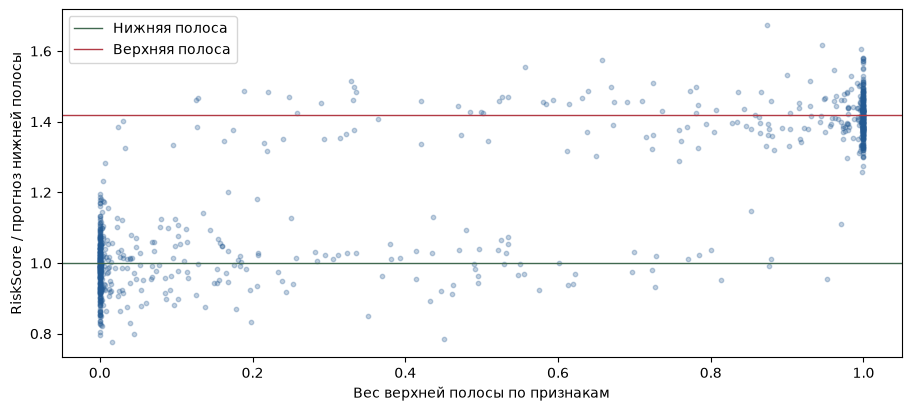

In [18]:
with threadpool_limits(limits=1):
    diagnostic = RiskScorecard().fit(X_fit, y_fit)

lower = scorecard_design(X_valid).to_numpy() @ diagnostic.coef_
weight = upper_band_weight(X_valid)
ratio = y_valid / lower
positions = np.random.default_rng(SEED).choice(len(ratio), size=900, replace=False)
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
ax.scatter(weight[positions], ratio[positions], s=10, alpha=.28, color='#245a92')
ax.axhline(1, color='#416950', linewidth=1, label='Нижняя полоса')
ax.axhline(1 + diagnostic.kappa_, color='#b23a45', linewidth=1, label='Верхняя полоса')
ax.set(xlabel='Вес верхней полосы по признакам', ylabel='RiskScore / прогноз нижней полосы')
ax.legend()
plt.show()

Обе полосы видны на отложенных строках. В середине диапазона веса встречаются наблюдения из обеих полос, поэтому при оценке по MSE полезно усреднять их прогнозы. Жёсткий выбор полосы дал бы скачок прогноза на границе.

### 6.4. Вневыборочная оценка

In [19]:
CV_SEEDS = (42, 2026, 41853)
methods = {
    'МНК, базовые признаки': predict_fold,
    'Ridge, расширенные признаки': lambda A, t, B: predict_fold(A, t, B, extended=True, alpha=RIDGE_ALPHA),
    'Карта, жёсткие метки': lambda A, t, B: RiskScorecard(soft=False).fit(A, t).predict(B),
    'Карта, взвешенный МНК': lambda A, t, B: RiskScorecard().fit(A, t).predict(B),
}

rows, predictions = [], {}
with threadpool_limits(limits=1):
    for name, fit_predict in methods.items():
        for seed in CV_SEEDS:
            folds, oof = cross_validate(X, y, k_fold(len(y), 5, shuffle=True, random_state=seed), fit_predict)
            predictions[name, seed] = oof
            rows.append({
                'Модель': name,
                'Разбиение': seed,
                **{metric_name: metric(y, oof) for metric_name, metric in metrics.items()},
                'MSE по фолдам': np.round(folds['MSE'].to_numpy(), 3).tolist(),
            })

evaluation = pd.DataFrame(rows)
mean_scores = evaluation.groupby('Модель', sort=False)[list(metrics)].mean().sort_values('MSE')
display(mean_scores.round(4))
display(evaluation[['Модель', 'Разбиение', 'MSE', 'MSE по фолдам']].round(4))

,MSE,MAE,R²,MAPE
Модель,,,,
"Карта, взвешенный МНК",17.9176,2.9286,0.9397,0.0680
"Карта, жёсткие метки",17.9352,2.9304,0.9397,0.0678
"Ridge, расширенные признаки",22.9468,3.5365,0.9228,0.0818
"МНК, базовые признаки",50.7288,5.7182,0.8294,0.1343


,Модель,Разбиение,MSE,MSE по фолдам
0,"МНК, базовые признаки",42,50.5706,"[50.952, 49.966, 47.091, 54.904, 49.94]"
1,"МНК, базовые признаки",2026,50.8192,"[49.885, 49.21, 49.808, 53.632, 51.562]"
2,"МНК, базовые признаки",41853,50.7966,"[50.714, 51.942, 51.158, 48.965, 51.203]"
3,"Ridge, расширенные признаки",42,22.9511,"[21.354, 22.839, 22.935, 24.805, 22.823]"
4,"Ridge, расширенные признаки",2026,23.0082,"[23.301, 23.593, 22.177, 22.317, 23.653]"
5,"Ridge, расширенные признаки",41853,22.8813,"[23.539, 24.091, 22.877, 21.879, 22.019]"
6,"Карта, жёсткие метки",42,17.9400,"[17.145, 17.877, 17.962, 19.275, 17.441]"
7,"Карта, жёсткие метки",2026,17.9271,"[17.637, 19.283, 17.876, 17.322, 17.516]"
8,"Карта, жёсткие метки",41853,17.9385,"[19.869, 18.461, 17.876, 16.138, 17.349]"
9,"Карта, взвешенный МНК",42,17.9221,"[17.144, 17.844, 17.933, 19.264, 17.426]"


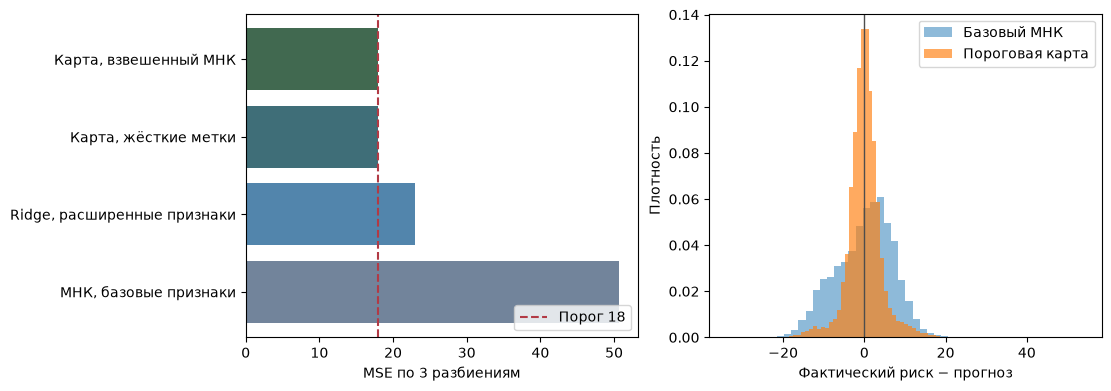

In [20]:
final_name = 'Карта, взвешенный МНК'
first_seed = CV_SEEDS[0]
base_pred = predictions['МНК, базовые признаки', first_seed]
final_pred = predictions[final_name, first_seed]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout='constrained')
colors = ['#72849b', '#5285ac', '#3f6e78', '#416950']
axes[0].barh(list(mean_scores.index)[::-1], mean_scores['MSE'].iloc[::-1], color=colors)
axes[0].axvline(18, color='#b23a45', linestyle='--', label='Порог 18')
axes[0].set_xlabel('MSE по 3 разбиениям')
axes[0].legend(loc='lower right')
axes[1].hist(y - base_pred, bins=50, density=True, alpha=.5, label='Базовый МНК')
axes[1].hist(y - final_pred, bins=50, density=True, alpha=.66, label='Пороговая карта')
axes[1].axvline(0, color='0.3', linewidth=1)
axes[1].set(xlabel='Фактический риск − прогноз', ylabel='Плотность')
axes[1].legend()
plt.show()

По результатам кросс-валидации для посылки используем взвешенный МНК на пороговой карте. Средние по трём разбиениям позволяют сравнить подходы на этих данных. Разброс по отдельным фолдам показывает, что прохождение порога на Kaggle требует отдельной проверки после отправки.

## 7. Финальное обучение и файл для Kaggle

In [21]:
with threadpool_limits(limits=1):
    final_model = RiskScorecard().fit(X, y)
    test_predictions = final_model.predict(test.loc[:, columns])

submission = example[['ID']].copy()
submission[TARGET] = submission['ID'].map(pd.Series(test_predictions, index=test['ID']))
assert list(submission.columns) == ['ID', TARGET]
assert len(submission) == len(test) and np.isfinite(submission[TARGET]).all()
submission.to_csv(DATA / 'submission.csv', index=False)

display(submission.head())
print(f'Строк в посылке: {len(submission):,}')
print(f'Множитель верхней полосы: {1 + final_model.kappa_:.3f}')
print(f'Средний локальный MSE: {mean_scores.loc[final_name, "MSE"]:.4f}')

,ID,RiskScore
0,0,32.991108
1,1,53.375214
2,2,30.005965
3,3,34.910057
4,4,33.024473


Строк в посылке: 5,000
Множитель верхней полосы: 1.417
Средний локальный MSE: 17.9176
